# Module 01: The Lazy Randomization
**Systematic spatial bias disguised as a miracle treatment effect** · *~5 min*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lunganlungpg/experimental-design-gone-wrong/blob/main/01_the_lazy_randomization/01_the_lazy_randomization.ipynb)


## 1. The Setup (The Blunder)

At 7:00 AM on a Monday, an exhausted botany grad student decides to test a pricey foliar spray (`BioBoost-X`) against plain tap water (`Control`) on 40 potted basil plants lined up along a single greenhouse bench. Because hauling a 10-liter watering can all the way down the aisle sounds suspiciously like cardio, they spray the first 20 pots sitting right next to the warm, sun-drenched south glass door and leave the back 20 pots shivering underneath the industrial HVAC chiller vent. They dutifully record `treatment` and `biomass_g`, ignore `bench_pos` completely, and start drafting an email to their advisor titled *'Possible Nature Paper?'*.

In [1]:
# Works locally out of the box; in Google Colab, clones the repo for src/.
import subprocess
import sys
from pathlib import Path

GITHUB_REPO = "lunganlungpg/experimental-design-gone-wrong"

for root in (Path.cwd(), Path.cwd().parent):
    if (root / "src" / "simulate_blunders.py").exists():
        if str(root) not in sys.path:
            sys.path.insert(0, str(root))
        break
else:
    clone_dir = Path("/content/experimental-design-gone-wrong")
    if not clone_dir.exists():
        subprocess.run(
            ["git", "clone", "-q", f"https://github.com/{GITHUB_REPO}.git", str(clone_dir)],
            check=True,
        )
    sys.path.insert(0, str(clone_dir))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

from src.simulate_blunders import (
    PALETTE,
    build_comparison_table,
    format_p_value,
    set_publication_style,
    simulate_lazy_randomization,
)

set_publication_style()
df = simulate_lazy_randomization(seed=42)
df.head(6)

,pot_id,bench_pos,sunlight_pct,treatment,biomass_g
0,1,1,96.5,BioBoost-X,55.53
1,2,2,92.7,BioBoost-X,54.42
2,3,3,94.5,BioBoost-X,50.49
3,4,4,93.3,BioBoost-X,52.45
4,5,5,86.7,BioBoost-X,51.58
5,6,6,86.4,BioBoost-X,51.31


## 2. The Crime (Naive Analysis)

Assuming all 40 pots experienced identical growing conditions, our sleep-deprived hero runs a classic independent two-sample *t*-test (`df = 38`). Let's watch the fake significance roll in.

In [2]:
ctrl = df.loc[df["treatment"] == "Control", "biomass_g"]
trt = df.loc[df["treatment"] == "BioBoost-X", "biomass_g"]

t_stat, p_naive = stats.ttest_ind(trt, ctrl)
naive_ols = smf.ols("biomass_g ~ C(treatment)", data=df).fit()
naive_est = naive_ols.params["C(treatment)[T.BioBoost-X]"]
naive_ci = naive_ols.conf_int().loc["C(treatment)[T.BioBoost-X]"].tolist()

print(f"Control mean   : {ctrl.mean():.2f} g (n = {len(ctrl)})")
print(f"BioBoost-X mean: {trt.mean():.2f} g (n = {len(trt)})")
print(f"Naive t({int(naive_ols.df_resid)})  = {t_stat:.2f}, p = {format_p_value(p_naive)}  <-- Champagne popped!")
print(f"Claimed boost  : +{naive_est:.2f} g  (95% CI: [{naive_ci[0]:.2f}, {naive_ci[1]:.2f}])")

Control mean   : 36.96 g (n = 20)
BioBoost-X mean: 48.56 g (n = 20)
Naive t(38)  = 9.47, p = 1.52e-11  <-- Champagne popped!
Claimed boost  : +11.60 g  (95% CI: [9.12, 14.07])


## 3. The Reality Check (Visual Punchline)

Left: the slide shown at lab meeting. Right: what happens the moment you plot `biomass_g` against `bench_pos` along the greenhouse bench.

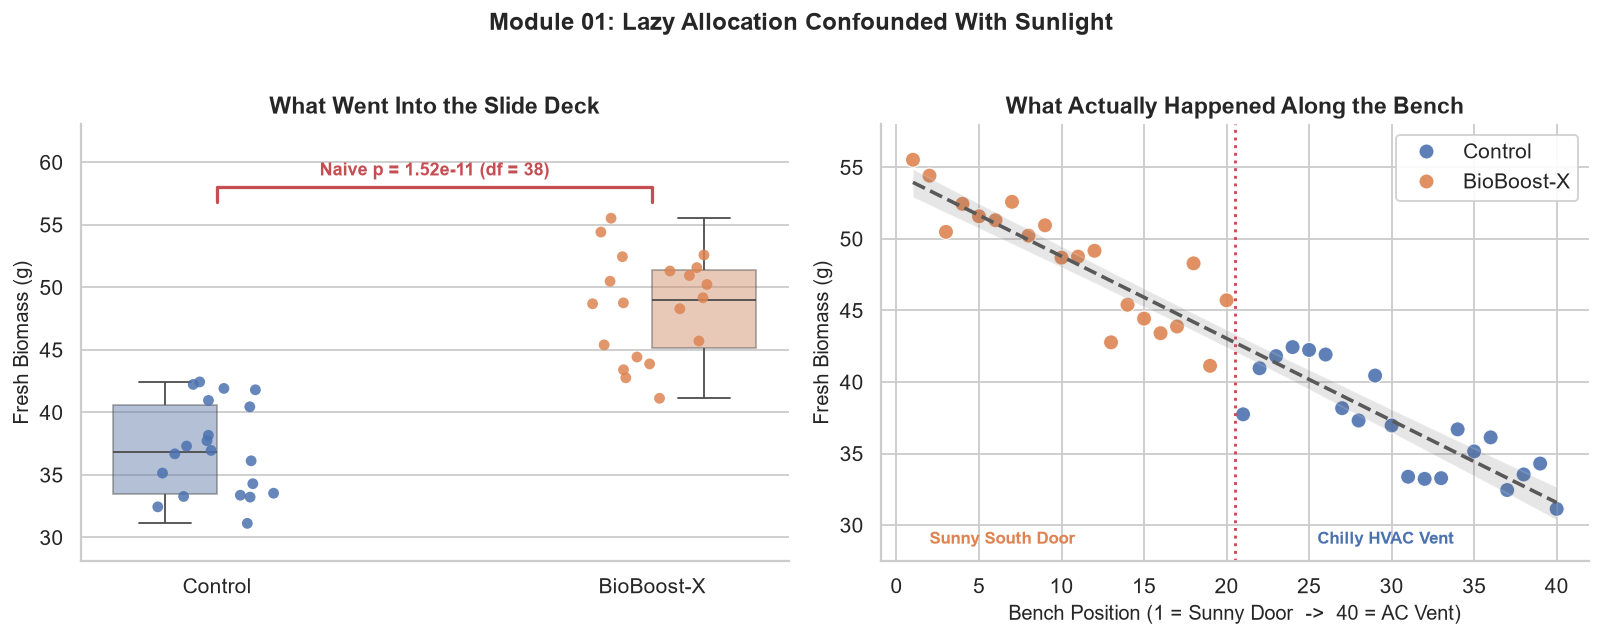

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
palette_map = {"Control": PALETTE["control"], "BioBoost-X": PALETTE["treated"]}

# Panel A: The Grant-Report Illusion
sns.boxplot(
    data=df, x="treatment", y="biomass_g", hue="treatment",
    palette=palette_map, width=0.48, boxprops={"alpha": 0.45}, legend=False, ax=axes[0]
)
sns.stripplot(
    data=df, x="treatment", y="biomass_g", hue="treatment",
    palette=palette_map, size=6, alpha=0.85, jitter=0.14, legend=False, ax=axes[0]
)
y_top = df["biomass_g"].max() + 2.5
axes[0].plot([0, 0, 1, 1], [y_top - 1.2, y_top, y_top, y_top - 1.2], color=PALETTE["danger"], lw=1.8)
axes[0].text(
    0.5, y_top + 0.6, f"Naive p = {format_p_value(p_naive)} (df = 38)",
    ha="center", va="bottom", color=PALETTE["danger"], fontweight="bold", fontsize=10,
)
axes[0].set_ylim(df["biomass_g"].min() - 3, y_top + 5)
axes[0].set_title("What Went Into the Slide Deck")
axes[0].set_xlabel("")
axes[0].set_ylabel("Fresh Biomass (g)")

# Panel B: The Hidden Greenhouse Gradient
sns.scatterplot(
    data=df, x="bench_pos", y="biomass_g", hue="treatment",
    palette=palette_map, s=70, alpha=0.9, edgecolor="white", ax=axes[1]
)
sns.regplot(
    data=df, x="bench_pos", y="biomass_g", scatter=False,
    color=PALETTE["neutral"], line_kws={"ls": "--", "lw": 2, "label": "Single Bench Slope"}, ax=axes[1]
)
axes[1].axvline(20.5, color=PALETTE["danger"], ls=":", lw=1.6)
axes[1].set_ylim(27.5, 58.0)
axes[1].text(2.0, 28.7, "Sunny South Door", fontsize=9.5, color=PALETTE["treated"], fontweight="bold")
axes[1].text(25.5, 28.7, "Chilly HVAC Vent", fontsize=9.5, color=PALETTE["control"], fontweight="bold")
axes[1].set_title("What Actually Happened Along the Bench")
axes[1].set_xlabel("Bench Position (1 = Sunny Door  ->  40 = AC Vent)")
axes[1].set_ylabel("Fresh Biomass (g)")
axes[1].legend(loc="upper right")

fig.suptitle("Module 01: Lazy Allocation Confounded With Sunlight", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 4. The Fix (Proper Model)

If we include `bench_pos` in an **ANCOVA / Spatial-Trend OLS** (`biomass_g ~ C(treatment) + bench_pos`), the continuous bench slope absorbs the sunlight cliff and checks whether any step-jump exists between `BioBoost-X` and `Control` at pot 20.5. Spoiler: the +11.6 g miracle vanishes into noise (and notice how collinearity also widens our uncertainty!).

In [4]:
ancova = smf.ols("biomass_g ~ C(treatment) + bench_pos", data=df).fit()
fix_est = ancova.params["C(treatment)[T.BioBoost-X]"]
fix_ci = ancova.conf_int().loc["C(treatment)[T.BioBoost-X]"].tolist()
fix_p = ancova.pvalues["C(treatment)[T.BioBoost-X]"]

summary = build_comparison_table(
    [
        {
            "Model": "Naive 2-Sample t-test / OLS",
            "Assumed Unit": "40 independent pots",
            "df_resid": int(naive_ols.df_resid),
            "Estimate": f"{naive_est:+.2f} g",
            "95% CI": f"[{naive_ci[0]:+.2f}, {naive_ci[1]:+.2f}]",
            "p_value": format_p_value(p_naive),
            "Verdict": "Fake miracle (p < 0.001)",
        },
        {
            "Model": "Proper Spatial ANCOVA (+ bench_pos)",
            "Assumed Unit": "40 pots adjusted for position",
            "df_resid": int(ancova.df_resid),
            "Estimate": f"{fix_est:+.2f} g",
            "95% CI": f"[{fix_ci[0]:+.2f}, {fix_ci[1]:+.2f}]",
            "p_value": format_p_value(fix_p),
            "Verdict": "Truth recovered (no effect)",
        },
    ]
)
summary

,Model,Assumed Unit,df_resid,Estimate,95% CI,p_value,Verdict
0,Naive 2-Sample t-test / OLS,40 independent pots,38,+11.60 g,"[+9.12, +14.07]",1.52e-11,Fake miracle (p < 0.001)
1,Proper Spatial ANCOVA (+ bench_pos),40 pots adjusted for position,37,+0.48 g,"[-2.18, +3.14]",0.7161,Truth recovered (no effect)


> **Rule of Thumb:** Randomize treatment assignments *physically* across space and time—never let convenience decide who sits by the window and who sits by the radiator. Statistical adjustment (`ANCOVA`) can sometimes unmask confounding afterward, but proper randomization before you touch a single pot prevents the bias *and* preserves your precision.